# Experiment 17: Scratch learning curves

Random initialisation; all layers and the shared NMR readout trained. Five dataset sizes: **10, 50, 100, 200 and 800 structures**, using the matched seed-42 subsets and the same 50 validation structures.

All five runs reached early stopping.

The overview contains five loss-versus-epoch panels and the method's best validation loss versus N. Individual plots follow. Gold points mark the saved best checkpoints; epoch numbering starts at 1. Loss axes are logarithmic, and histories are unsmoothed. These are one-seed exploratory validation results, not independent test performance.


## Loss and source data

The common loss is $\frac12[\mathrm{MSE}_{Si}/8.789599019755547^2 + \mathrm{MSE}_{O}/19.197689920683118^2]$, with overall weight 1.0. The fixed scales come from the original 800-structure training split.

**Training loss** is reconstructed from the logged full-epoch Si/O RMSE. It describes predictions made during training as weights change, not a fresh evaluation of one checkpoint on the training set. The sampled batch-level `train/loss/total` field is not used. **Validation loss** is the recorded full-validation loss for each completed epoch. Every selected loss was checked against its checkpoint and independently recomputed on the 50 validation structures. Partial final epochs are omitted.

The cells replot the saved CSV tables without a network connection or retraining. W&B links, input hashes and metric definitions are in `17-19-LearningCurve-data/provenance.json`.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT = Path(globals().get('PROJECT_ROOT', '/Users/louismcauliffe/code/research/NequIP_experiments'))
sys.path.insert(0, str(ROOT / 'analysis_helpers'))
from learning_curve_review import load_tables, plot_run, plot_method, plot_comparison, plot_rmse
runs, epochs = load_tables(ROOT)
FIGURES = ROOT / 'experiments' / '17-19-LearningCurve-figures'

display(runs[runs.experiment == 17][['n','best_valid_loss','Si_rmse','O_rmse','best_epoch','final_epoch','status']].round(6))


,n,best_valid_loss,Si_rmse,O_rmse,best_epoch,final_epoch,status
0,10,0.285961,4.615855,10.447205,62,362,Early stopping
1,50,0.111786,3.083778,6.085355,90,390,Early stopping
2,100,0.080717,2.649567,5.099450,110,410,Early stopping
3,200,0.037884,1.816933,3.488954,114,414,Early stopping
4,800,0.010183,0.832985,2.048360,237,537,Early stopping


## Overview

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


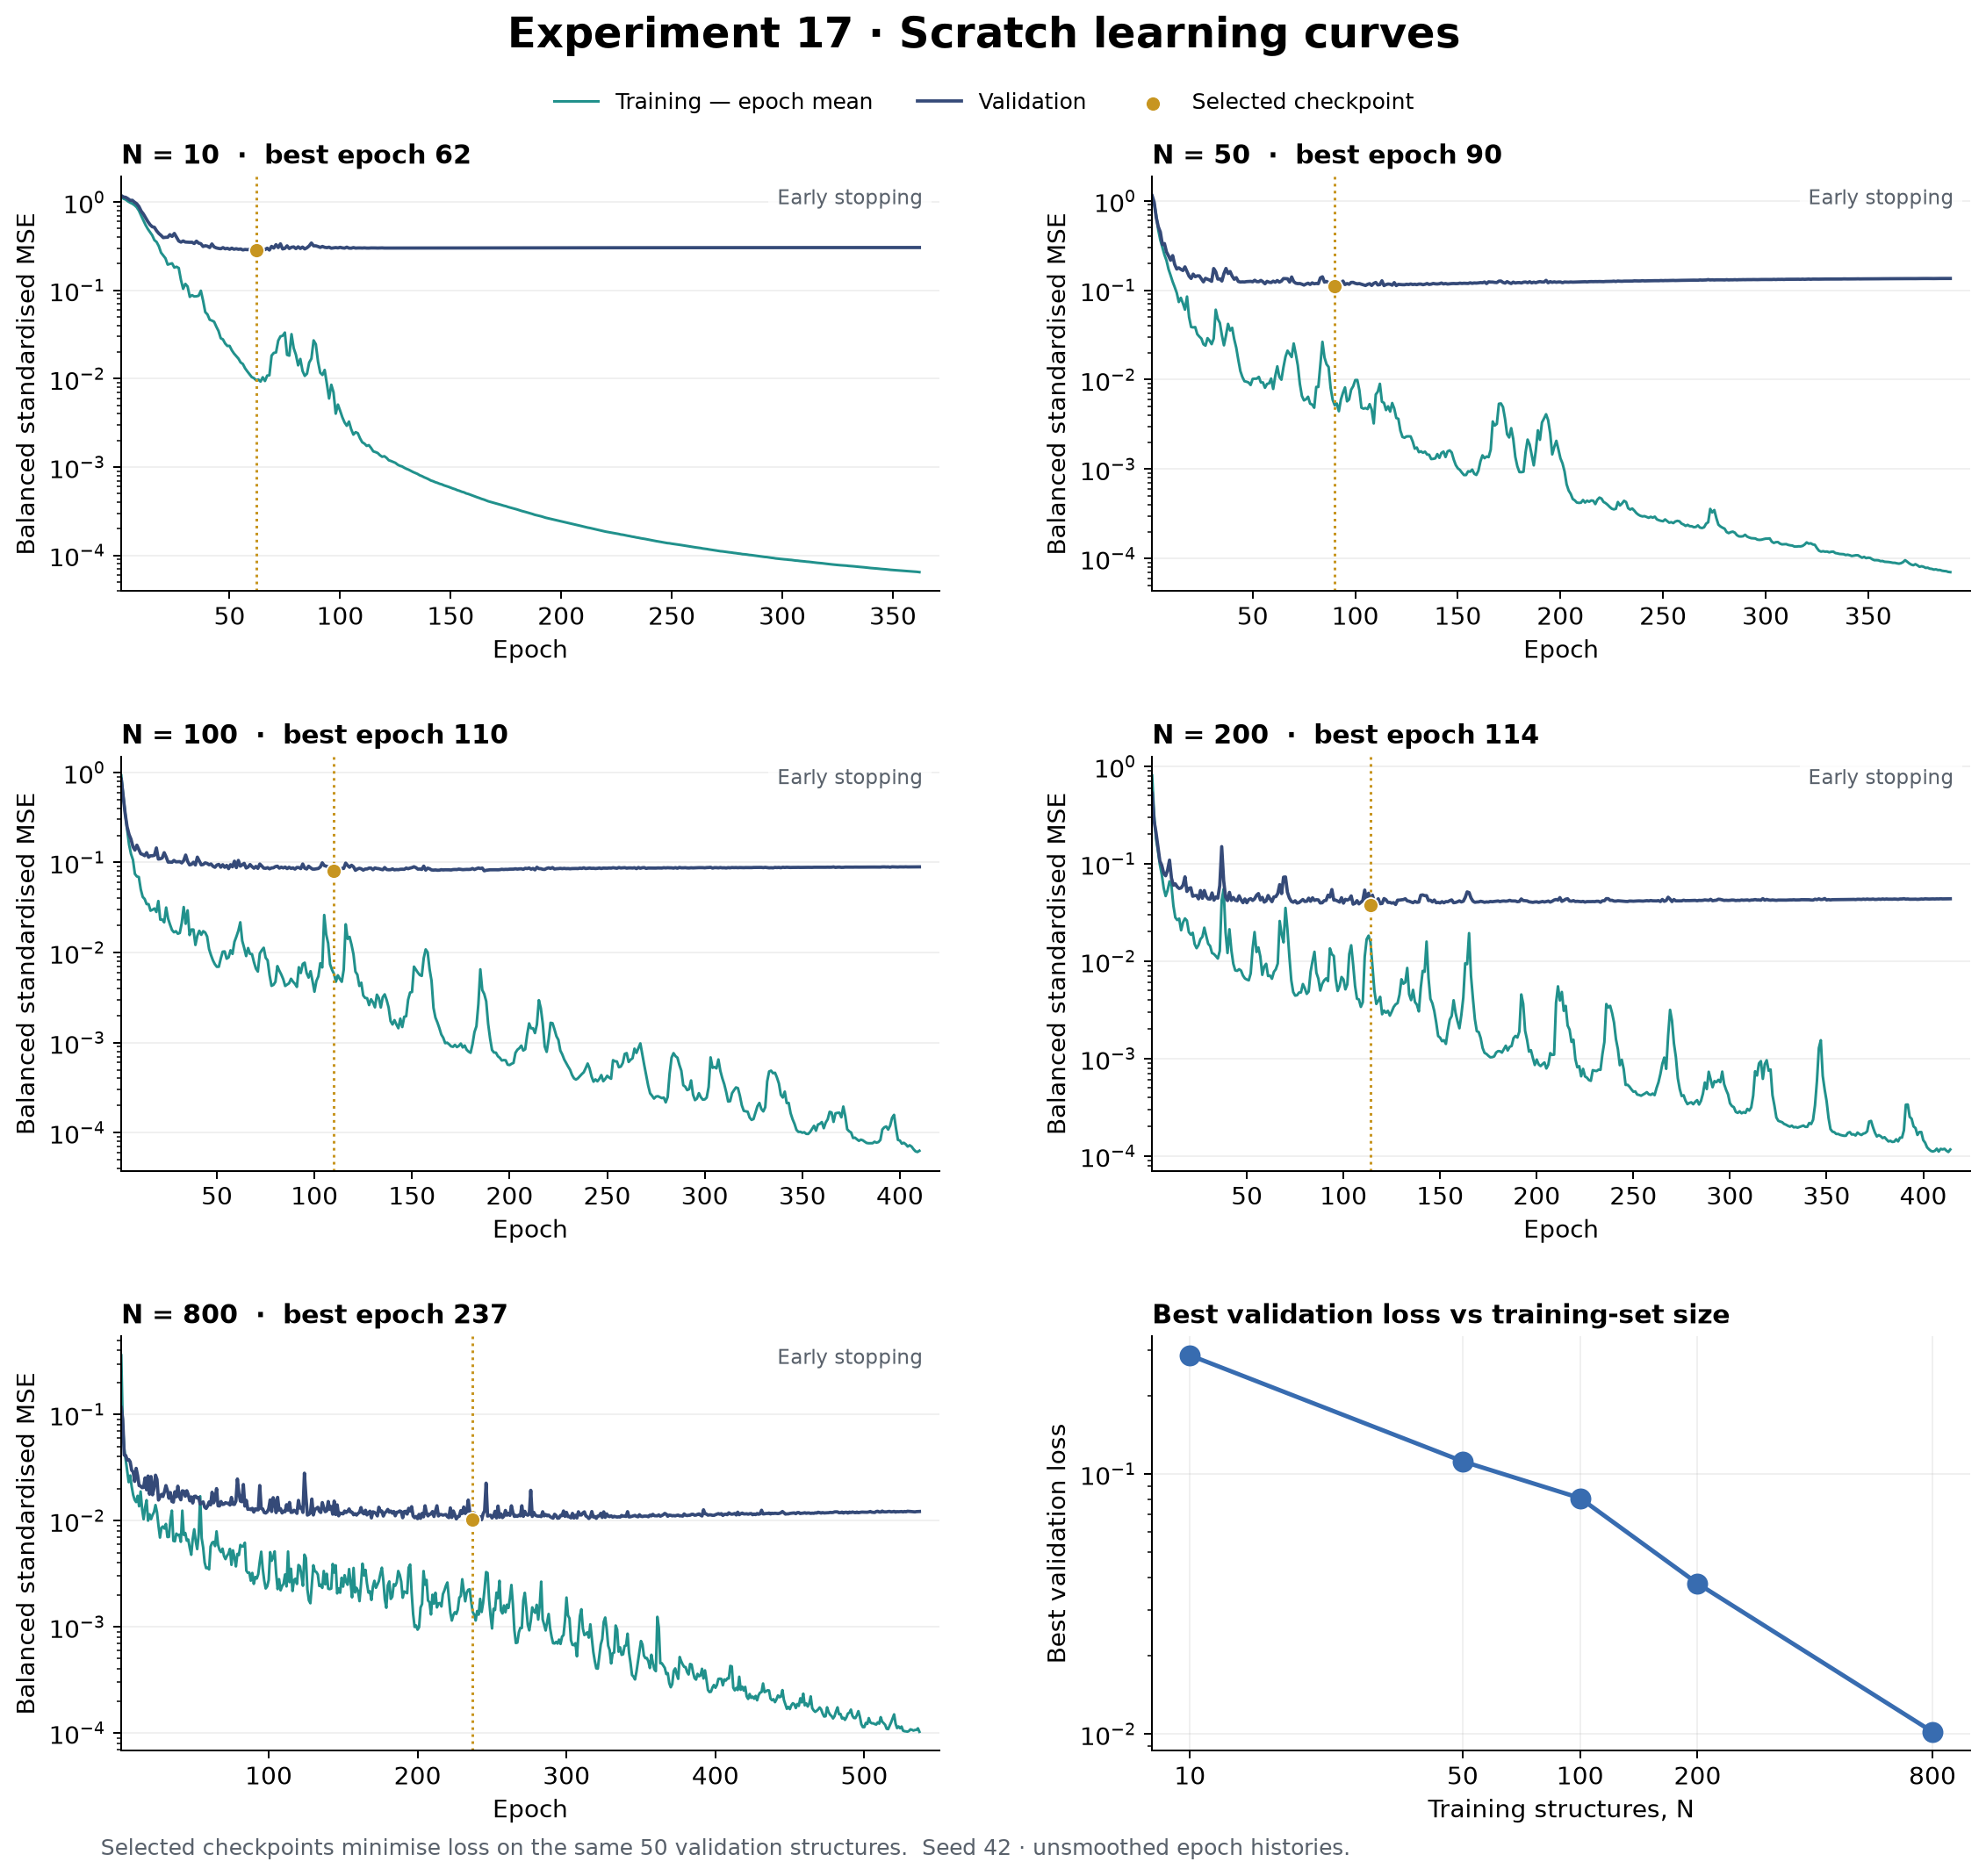

In [2]:
display(Image(filename=str(plot_method(runs, epochs, 17, FIGURES))))


## Individual training histories

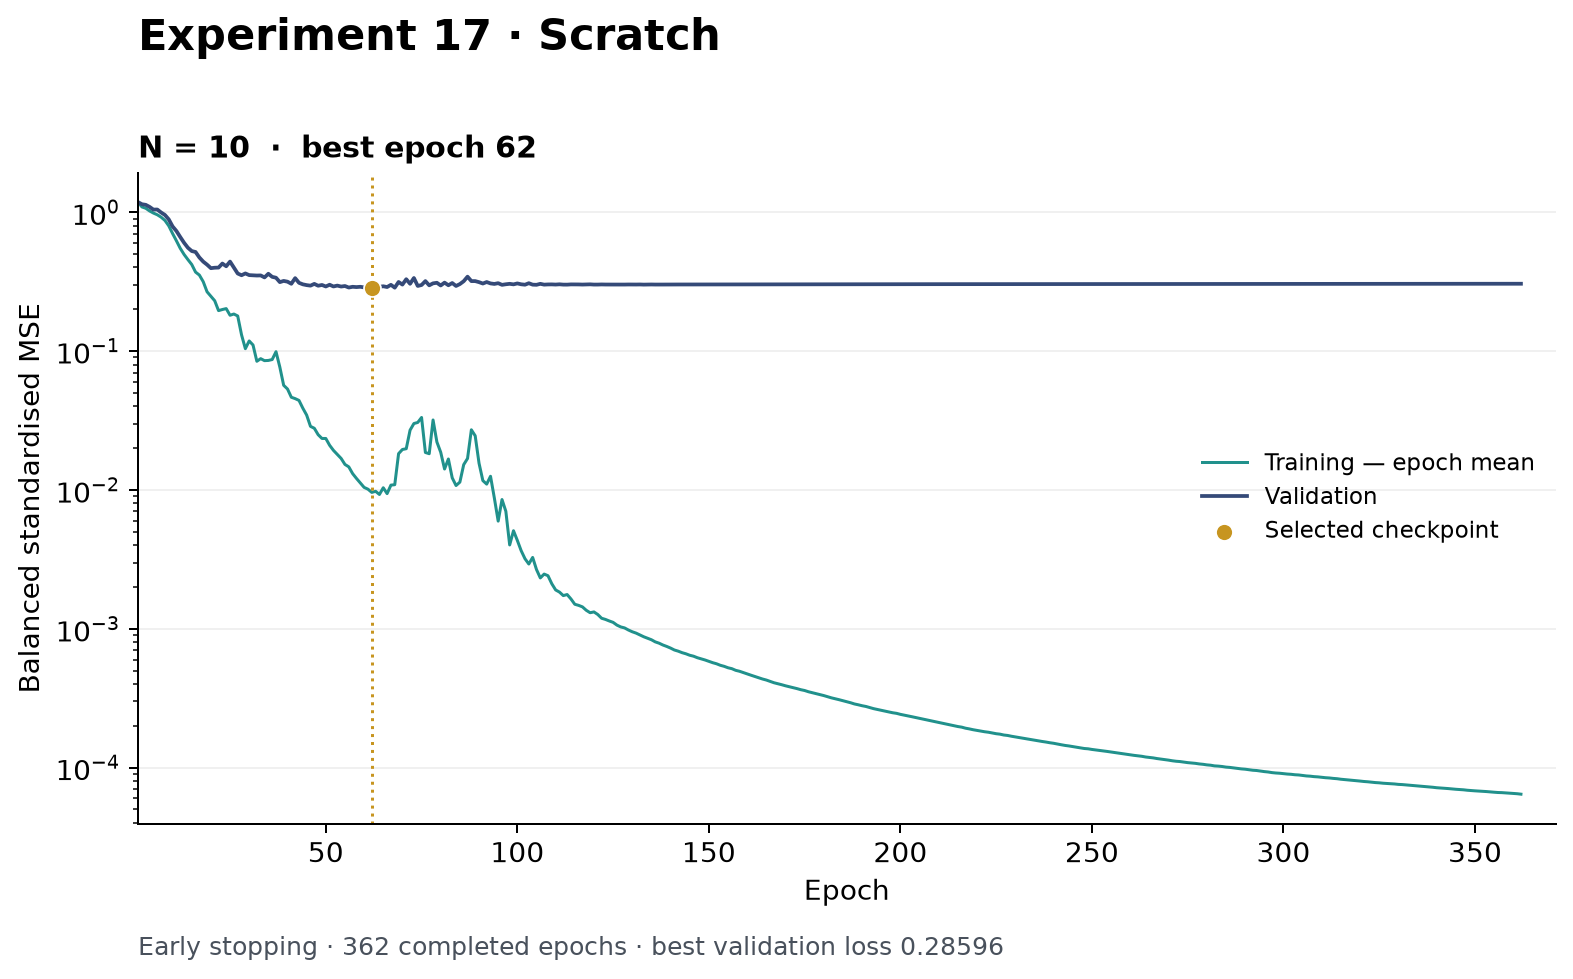

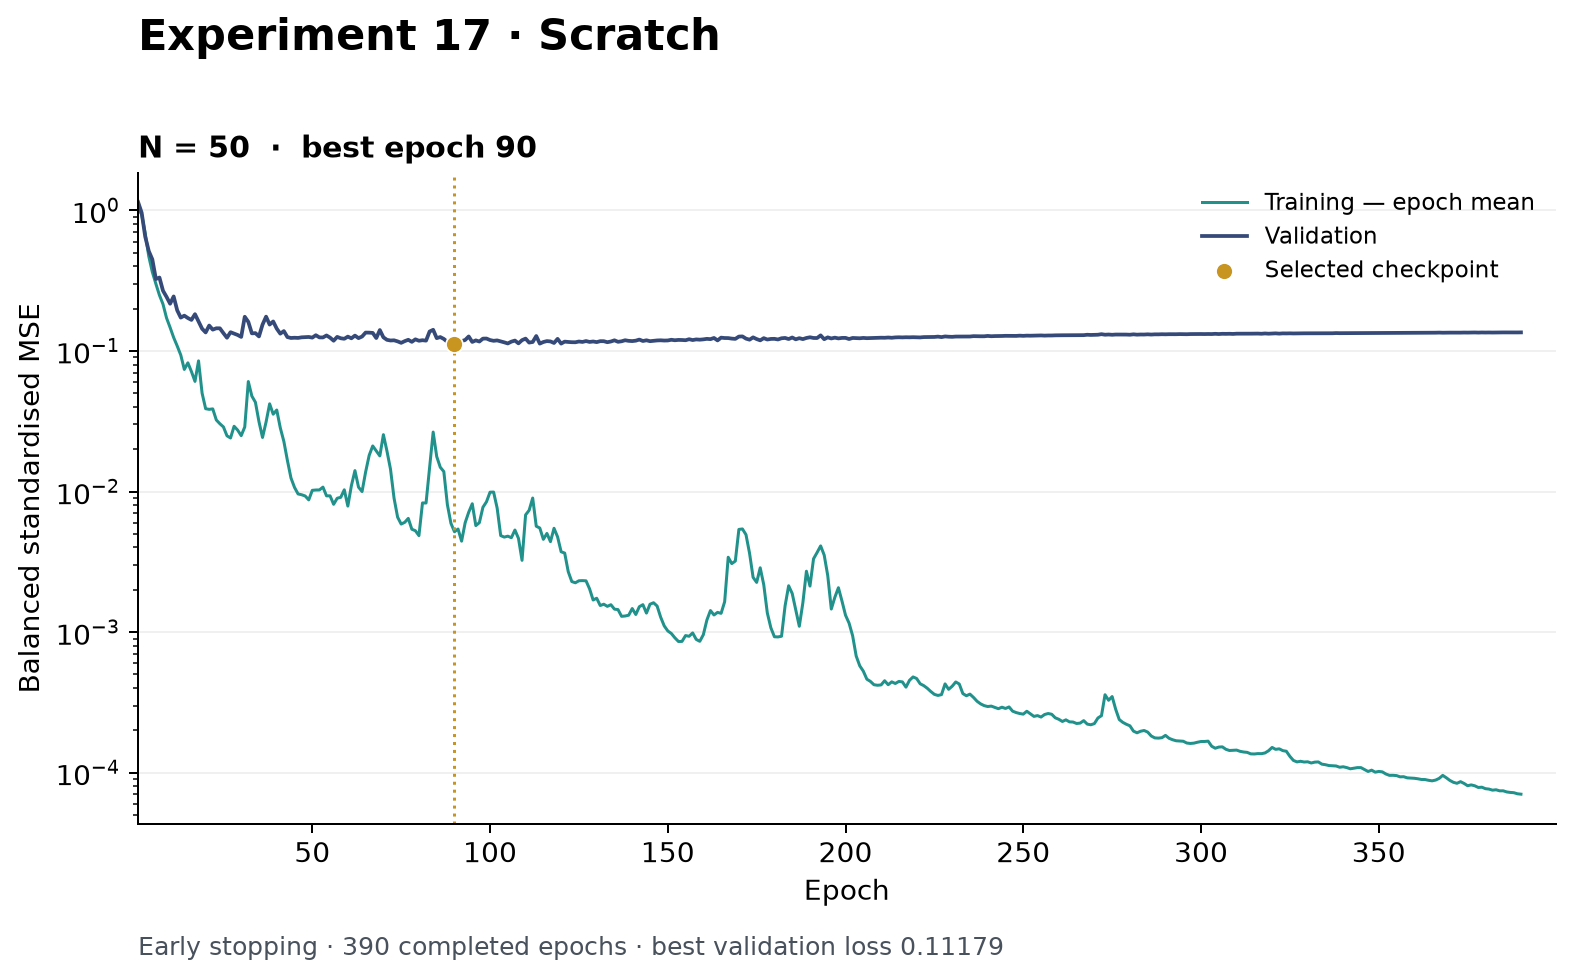

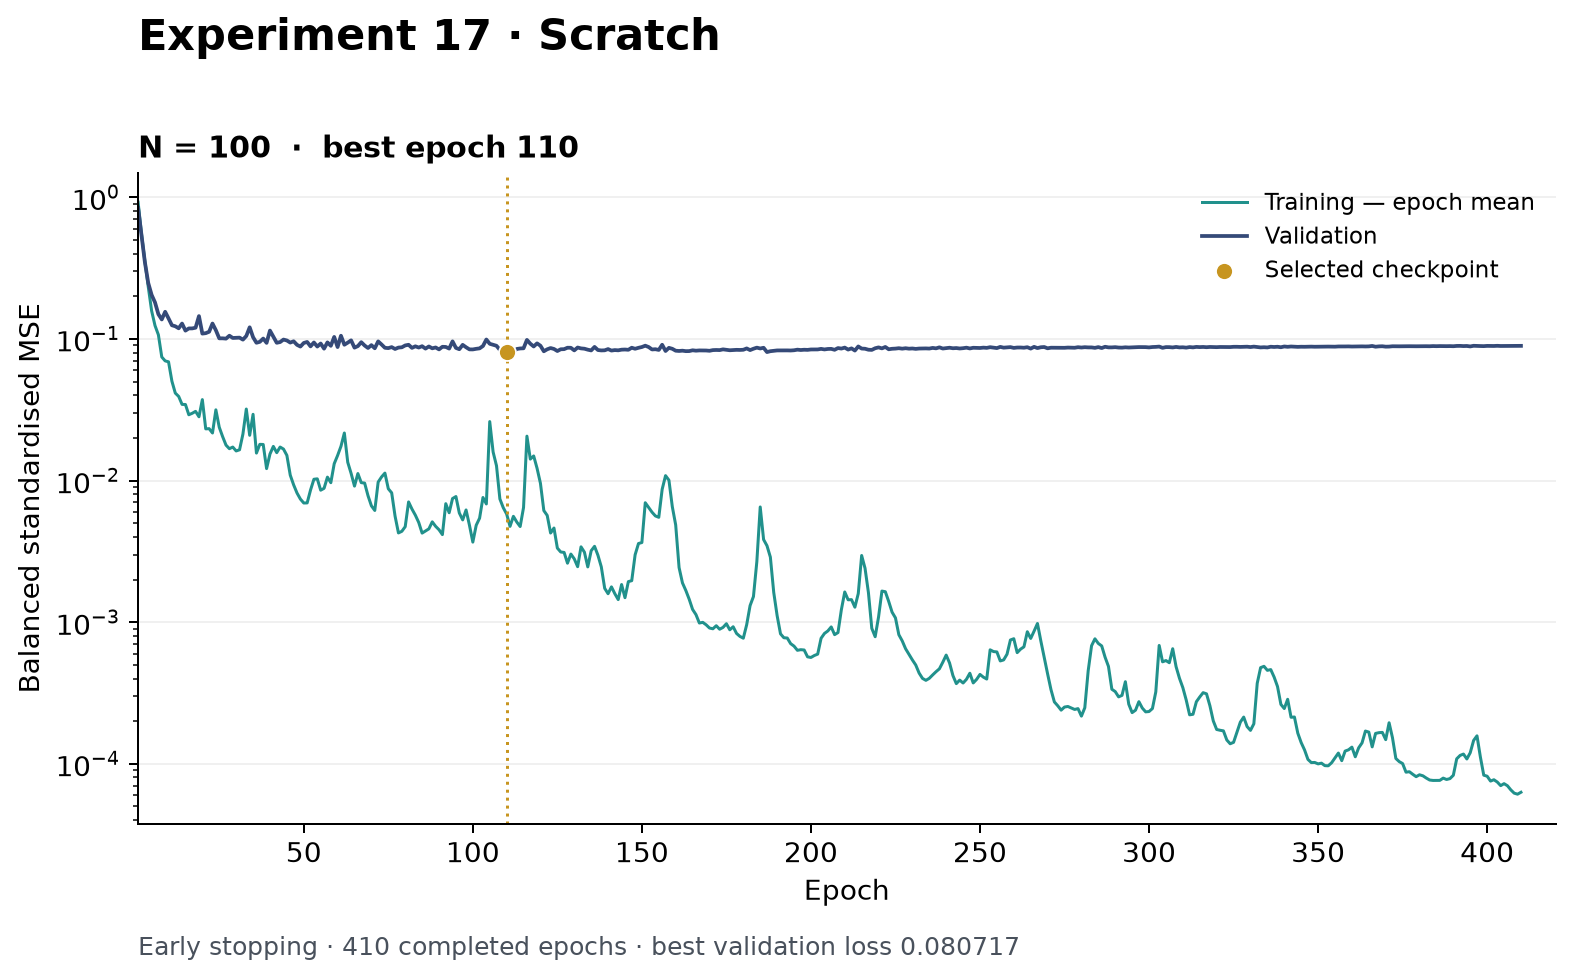

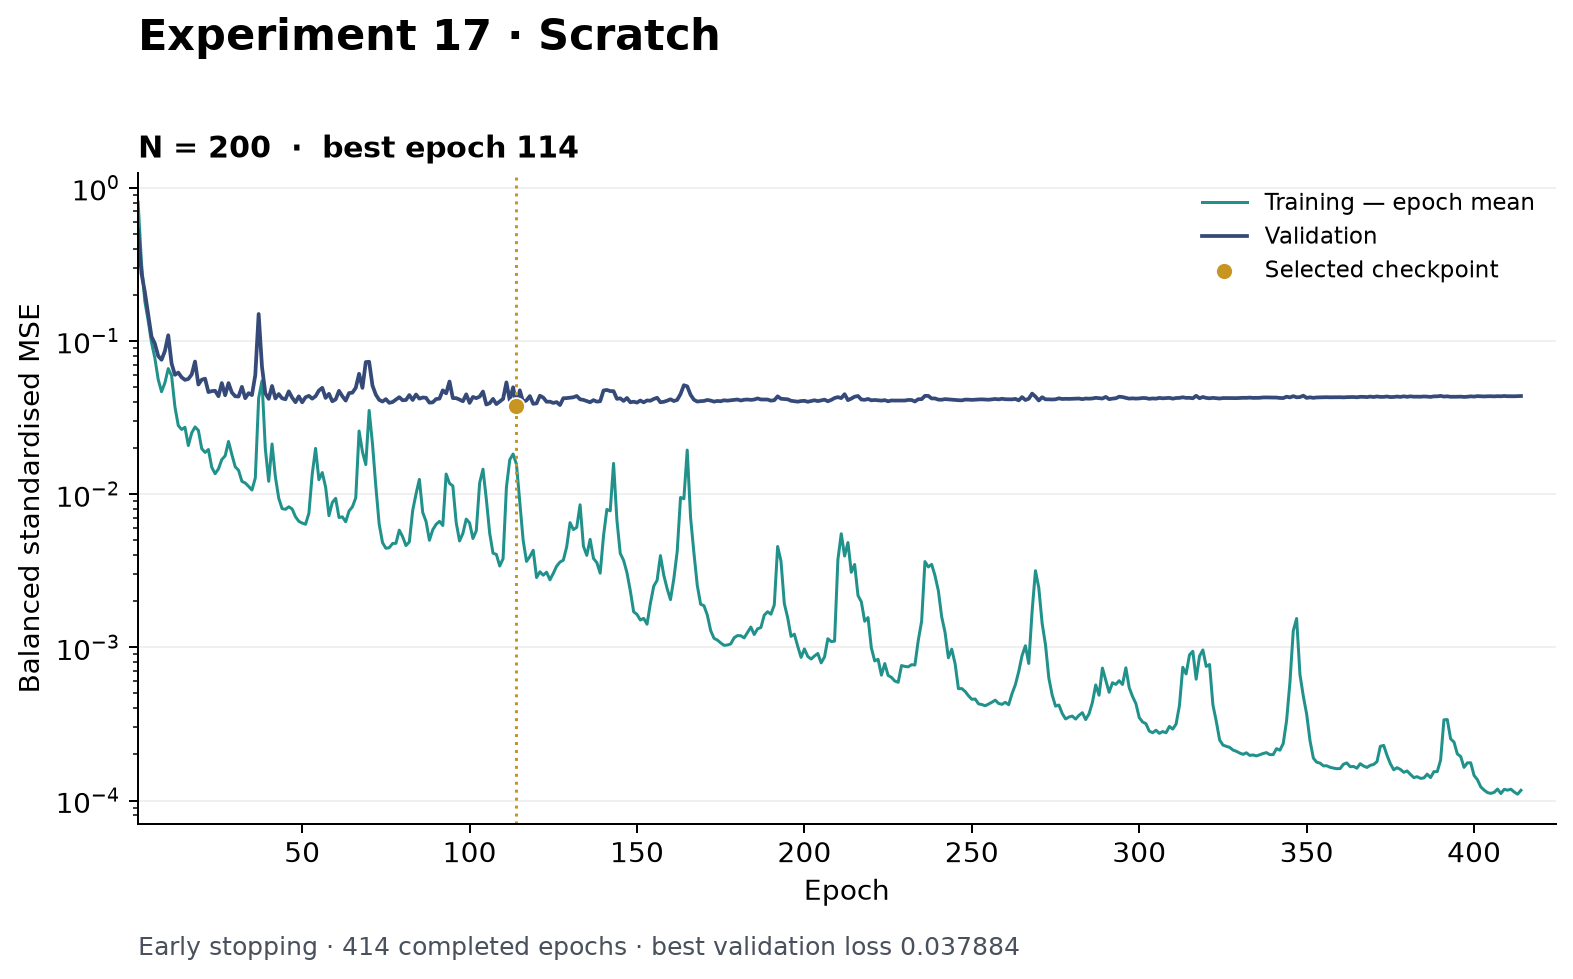

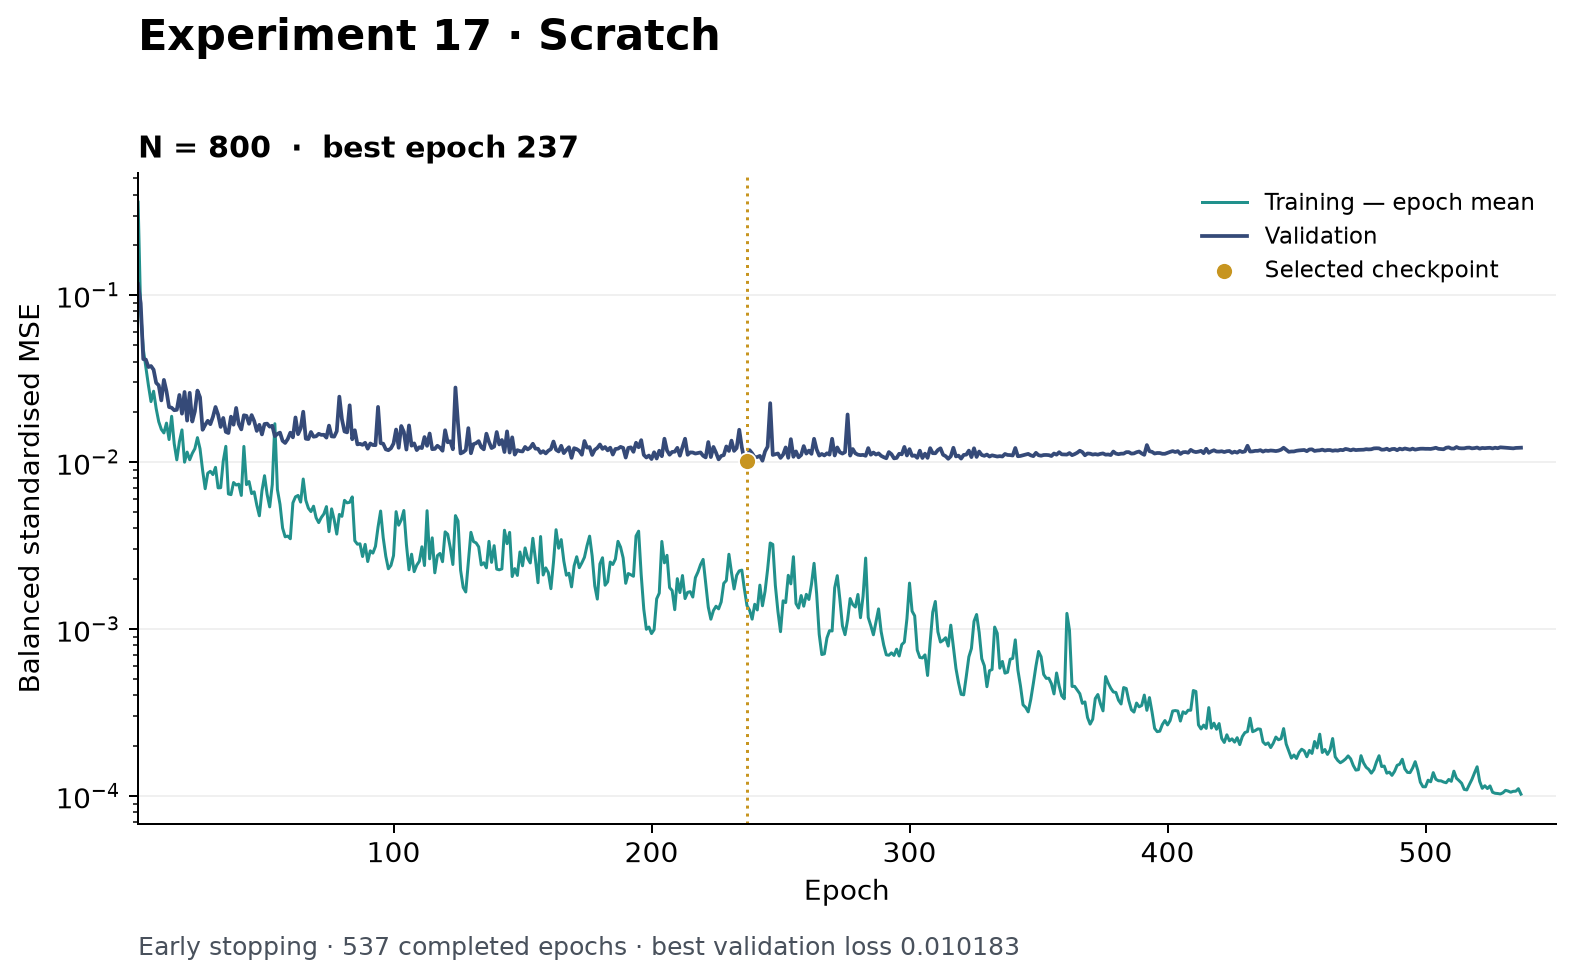

In [3]:
for run_id in runs[runs.experiment == 17].sort_values('n').run_id:
    display(Image(filename=str(plot_run(runs, epochs, run_id, FIGURES))))
